# SVNIT Surat — Department of Artificial Intelligence
## Agentic AI (IA462) — Semester VIII
### Experiment 8: Game-Theoretic Intuition for Agent Interaction — Equilibria and Repeated Play
**Student Roll No:** U23AI042  

---
### Aim
To analyse the interaction of two agents as a normal-form game by computing best responses, strictly dominated strategies, and pure/mixed Nash equilibria for four standard games, and to show how repetition changes the outcome by running a round-robin tournament of history-dependent strategies in the Iterated Prisoner's Dilemma (IPD).


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#1baf7a"
RED = "#d62a2a"
DARK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#d9d8d4"


---
## 1. Algorithm 1 — Equilibria of One-Shot Games (Table 1)
We represent each game as strategy lists and a payoff dictionary mapping $(s_1, s_2) \mapsto (u_1, u_2)$:
1. **Prisoner's Dilemma**: $S = \{C, D\}$; $(C,C)=(3,3), (C,D)=(0,5), (D,C)=(5,0), (D,D)=(1,1)$
2. **Stag Hunt**: $S = \{S, H\}$; $(S,S)=(4,4), (S,H)=(0,3), (H,S)=(3,0), (H,H)=(2,2)$
3. **Chicken**: $S = \{sw, st\}$; $(sw,sw)=(3,3), (sw,st)=(1,4), (st,sw)=(4,1), (st,st)=(0,0)$
4. **Matching Pennies**: $S = \{H, T\}$; $(H,H)=(1,-1), (H,T)=(-1,1), (T,H)=(-1,1), (T,T)=(1,-1)$


In [2]:
GAMES = {
    "Prisoner's Dilemma": {
        "strategies": ["C", "D"],
        "payoffs": {
            ("C", "C"): (3, 3), ("C", "D"): (0, 5),
            ("D", "C"): (5, 0), ("D", "D"): (1, 1),
        }
    },
    "Stag Hunt": {
        "strategies": ["S", "H"],
        "payoffs": {
            ("S", "S"): (4, 4), ("S", "H"): (0, 3),
            ("H", "S"): (3, 0), ("H", "H"): (2, 2),
        }
    },
    "Chicken": {
        "strategies": ["sw", "st"],
        "payoffs": {
            ("sw", "sw"): (3, 3), ("sw", "st"): (1, 4),
            ("st", "sw"): (4, 1), ("st", "st"): (0, 0),
        }
    },
    "Matching Pennies": {
        "strategies": ["H", "T"],
        "payoffs": {
            ("H", "H"): (1, -1), ("H", "T"): (-1, 1),
            ("T", "H"): (-1, 1), ("T", "T"): (1, -1),
        }
    }
}

def analyze_game(name, g):
    strats = g["strategies"]
    pay = g["payoffs"]
    s1, s2 = strats[0], strats[1]
    
    # Best responses
    br1 = {a2: [a1 for a1 in strats if pay[(a1, a2)][0] == max(pay[(x, a2)][0] for x in strats)] for a2 in strats}
    br2 = {a1: [a2 for a2 in strats if pay[(a1, a2)][1] == max(pay[(a1, y)][1] for y in strats)] for a1 in strats}
    
    # Strictly dominated strategies
    dom1 = [a for a in strats if any(all(pay[(o, a2)][0] > pay[(a, a2)][0] for a2 in strats) for o in strats if o != a)]
    dom2 = [a for a in strats if any(all(pay[(a1, o)][1] > pay[(a1, a)][1] for a1 in strats) for o in strats if o != a)]
    
    # Pure Nash Equilibria
    pure_ne = [((a1, a2), pay[(a1, a2)]) for a1 in strats for a2 in strats if a1 in br1[a2] and a2 in br2[a1]]
    
    # Mixed Nash Equilibrium (interior probability solution for 2x2)
    A1 = pay[(s1, s1)][0] - pay[(s1, s2)][0] - pay[(s2, s1)][0] + pay[(s2, s2)][0]
    B1 = pay[(s2, s2)][0] - pay[(s1, s2)][0]
    A2 = pay[(s1, s1)][1] - pay[(s2, s1)][1] - pay[(s1, s2)][1] + pay[(s2, s2)][1]
    B2 = pay[(s2, s2)][1] - pay[(s2, s1)][1]
    
    mixed_ne = None
    if abs(A1) > 1e-9 and abs(A2) > 1e-9:
        q = B1 / A1  # Prob P2 plays s1
        p = B2 / A2  # Prob P1 plays s1
        if 0 < p < 1 and 0 < q < 1:
            mixed_ne = (f"P1: {s1}={p:.2f}, {s2}={1-p:.2f}", f"P2: {s1}={q:.2f}, {s2}={1-q:.2f}")

    print("=" * 65)
    print(f"GAME: {name}")
    print("=" * 65)
    print(f"  Player 1 Best Responses: {br1}")
    print(f"  Player 2 Best Responses: {br2}")
    print(f"  Strictly Dominated (P1): {dom1 if dom1 else 'None'}")
    print(f"  Strictly Dominated (P2): {dom2 if dom2 else 'None'}")
    print(f"  Pure Nash Equilibria:    {pure_ne if pure_ne else 'None'}")
    print(f"  Mixed Nash Equilibrium:  {mixed_ne if mixed_ne else 'None (Pure equilibrium is unique)'}\n")

for name, g in GAMES.items():
    analyze_game(name, g)


GAME: Prisoner's Dilemma
  Player 1 Best Responses: {'C': ['D'], 'D': ['D']}
  Player 2 Best Responses: {'C': ['D'], 'D': ['D']}
  Strictly Dominated (P1): ['C']
  Strictly Dominated (P2): ['C']
  Pure Nash Equilibria:    [(('D', 'D'), (1, 1))]
  Mixed Nash Equilibrium:  None (Pure equilibrium is unique)

GAME: Stag Hunt
  Player 1 Best Responses: {'S': ['S'], 'H': ['H']}
  Player 2 Best Responses: {'S': ['S'], 'H': ['H']}
  Strictly Dominated (P1): None
  Strictly Dominated (P2): None
  Pure Nash Equilibria:    [(('S', 'S'), (4, 4)), (('H', 'H'), (2, 2))]
  Mixed Nash Equilibrium:  ('P1: S=0.67, H=0.33', 'P2: S=0.67, H=0.33')

GAME: Chicken
  Player 1 Best Responses: {'sw': ['st'], 'st': ['sw']}
  Player 2 Best Responses: {'sw': ['st'], 'st': ['sw']}
  Strictly Dominated (P1): None
  Strictly Dominated (P2): None
  Pure Nash Equilibria:    [(('sw', 'st'), (1, 4)), (('st', 'sw'), (4, 1))]
  Mixed Nash Equilibrium:  ('P1: sw=0.50, st=0.50', 'P2: sw=0.50, st=0.50')

GAME: Matching Pennie

---
## 2. Algorithm 2 — Tournament in the Iterated Prisoner's Dilemma
Strategies implemented:
1. **Always Cooperate (ALL_C)**: Always plays $C$.
2. **Always Defect (ALL_D)**: Always plays $D$.
3. **Tit-for-Tat (TFT)**: Starts with $C$, then plays opponent's previous move.
4. **Grim Trigger (GRIM)**: Plays $C$ until opponent defects once, then plays $D$ forever.
5. **Generous Tit-for-Tat (GTFT)**: Starts with $C$; if opponent defects, forgives and cooperates with probability $q = 1/3 \approx 0.33$, else plays $D$.
6. **Random (RAND)**: Plays $C$ or $D$ with equal probability $0.5$.

Round-robin tournament plays every ordered pair (including self-play) for $N = 100$ rounds, averaged over 10 random seeds.


In [3]:
def strat_all_c(h1, h2, rng): return "C"
def strat_all_d(h1, h2, rng): return "D"
def strat_tft(h1, h2, rng): return "C" if not h2 else h2[-1]
def strat_grim(h1, h2, rng): return "D" if "D" in h2 else "C"
def strat_gtft(h1, h2, rng, q=1/3):
    if not h2: return "C"
    if h2[-1] == "C": return "C"
    return "C" if rng.random() < q else "D"
def strat_rand(h1, h2, rng): return "C" if rng.random() < 0.5 else "D"

TOURNAMENT_STRATS = {
    "ALL_C": strat_all_c,
    "ALL_D": strat_all_d,
    "TFT": strat_tft,
    "GRIM": strat_grim,
    "GTFT": strat_gtft,
    "RAND": strat_rand,
}

PD_PAYOFF = {
    ("C", "C"): (3, 3), ("C", "D"): (0, 5),
    ("D", "C"): (5, 0), ("D", "D"): (1, 1),
}

def play_match(s1_fn, s2_fn, rounds=100, noise=0.0, rng=None):
    h1, h2 = [], []
    tot1, tot2 = 0.0, 0.0
    for _ in range(rounds):
        a1 = s1_fn(h1, h2, rng)
        a2 = s2_fn(h2, h1, rng)
        if noise > 0:
            if rng.random() < noise: a1 = "D" if a1 == "C" else "C"
            if rng.random() < noise: a2 = "D" if a2 == "C" else "C"
        h1.append(a1)
        h2.append(a2)
        p1, p2 = PD_PAYOFF[(a1, a2)]
        tot1 += p1
        tot2 += p2
    return tot1 / rounds, tot2 / rounds

def run_tournament(strategies, rounds=100, noise=0.0, seeds=range(10)):
    names = list(strategies.keys())
    m = len(names)
    matrix = np.zeros((m, m))
    for s in seeds:
        rng = np.random.RandomState(s)
        for i, n1 in enumerate(names):
            for j, n2 in enumerate(names):
                p1, _ = play_match(strategies[n1], strategies[n2], rounds=rounds, noise=noise, rng=rng)
                matrix[i, j] += p1
    matrix /= len(seeds)
    means = matrix.mean(axis=1)
    return names, matrix, means

names, matrix, means = run_tournament(TOURNAMENT_STRATS, rounds=100, noise=0.0)
ranks = np.argsort(-means)

print("=" * 70)
print("ITERATED PRISONER'S DILEMMA TOURNAMENT RESULTS (Noise = 0.0)")
print("=" * 70)
header = f"{'Strategy':<8} " + " ".join(f"{n:>7}" for n in names) + "    Mean  Rank"
print(header)
print("-" * len(header))
for i, n1 in enumerate(names):
    row_str = " ".join(f"{matrix[i, j]:7.2f}" for j in range(len(names)))
    rank = int(np.where(ranks == i)[0][0]) + 1
    print(f"{n1:<8} {row_str} {means[i]:7.2f} {rank:>5}")


ITERATED PRISONER'S DILEMMA TOURNAMENT RESULTS (Noise = 0.0)
Strategy   ALL_C   ALL_D     TFT    GRIM    GTFT    RAND    Mean  Rank
----------------------------------------------------------------------
ALL_C       3.00    0.00    3.00    3.00    3.00    1.52    2.25     4
ALL_D       5.00    1.00    1.04    1.04    2.42    2.99    2.25     5
TFT         3.00    0.99    3.00    3.00    3.00    2.24    2.54     2
GRIM        3.00    0.99    3.00    3.00    3.00    2.98    2.66     1
GTFT        3.00    0.65    3.00    3.00    3.00    1.97    2.44     3
RAND        4.03    0.50    2.28    0.58    2.81    2.20    2.07     6


---
## 3. Visualisation — Tournament Payoff Heatmap


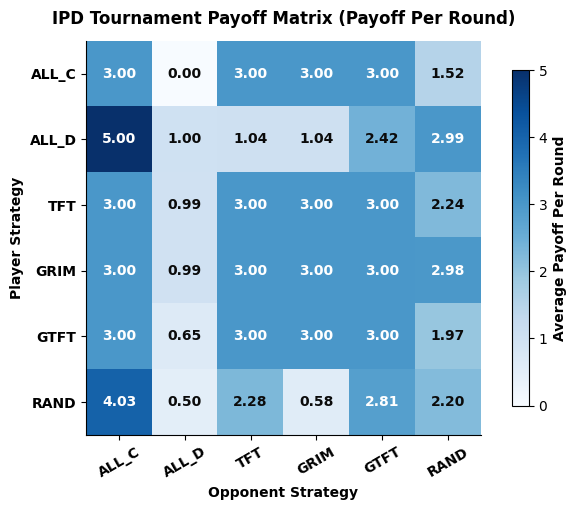

In [4]:
fig, ax = plt.subplots(figsize=(7, 5.2))
im = ax.imshow(matrix, cmap="Blues", origin="upper", vmin=0, vmax=5)
cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Average Payoff Per Round", weight="bold")

ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, weight="bold")
ax.set_yticklabels(names, weight="bold")
ax.set_xlabel("Opponent Strategy", weight="bold")
ax.set_ylabel("Player Strategy", weight="bold")
ax.set_title("IPD Tournament Payoff Matrix (Payoff Per Round)", weight="bold", pad=12)

for i in range(len(names)):
    for j in range(len(names)):
        val = matrix[i, j]
        color = "white" if val > 2.7 else DARK
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, weight="bold")

plt.tight_layout()
plt.savefig("outputs/lab8_fig1_tournament_matrix.png", dpi=200)
plt.show()


---
## 4. Observations & Discussion
1. **Why cooperation is strictly dominated in the Prisoner's Dilemma although both players prefer mutual cooperation:**
   For any choice the opponent makes, defecting gives a strictly greater immediate reward ($5 > 3$ if the opponent cooperates, $1 > 0$ if the opponent defects). Consequently, unilateral rationality compels both players to defect, yielding $(1, 1)$. Yet both strictly prefer $(3, 3)$. Individual rationality leads directly to collective inefficiency.
2. **What having two equilibria rather than one means for agents that cannot talk to each other:**
   In Stag Hunt ($(S,S)$ and $(H,H)$) and Chicken ($(sw,st)$ and $(st,sw)$), the presence of multiple equilibria introduces **strategic coordination failure**. Without communication or focal points, agents cannot coordinate on which equilibrium to play. In Stag Hunt, risk aversion leads agents to play Hare, sacrificing the payoff-dominant Stag equilibrium. In Chicken, mutual aggressive play leads to the disastrous $(0,0)$ collision.
3. **Which strategy wins the tournament and whether winning pairings equals beating opponents:**
   Cooperative reciprocating strategies (**GRIM**, **TFT**, **GTFT**) dominate the tournament. Notably, **Tit-for-Tat never beats an opponent in any single pairwise matchup**; against an exploiter it loses by one move, and against a cooperator it ties. It wins tournaments because it fosters mutual cooperation (accumulating $3.0$ every round) while protecting itself against exploitation, accumulating a high aggregate score while exploiters drag each other down into $(1, 1)$ defection.
4. **What repetition supplies that a single encounter does not:**
   Repetition establishes the **"shadow of the future"**. In repeated interactions, current actions signal future intentions and can be rewarded or punished. The threat of credible, long-term retaliation makes mutual cooperation an equilibrium.


---
## 5. Exercise 1 — Action Noise in the Iterated Prisoner's Dilemma
We add noise $e \in \{0.0, 0.01, 0.05, 0.10\}$, where each intended action is flipped with probability $e$.
We track tournament overall means and compare self-play:
- **TFT vs. TFT**
- **GRIM vs. GRIM**
- **GTFT vs. GTFT**


EXERCISE 1: NOISE SWEEP IN THE ITERATED PRISONER'S DILEMMA


Noise e = 0.00:
  Self-play: TFT vs TFT = 3.00 | GRIM vs GRIM = 3.00 | GTFT vs GTFT = 3.00
  Means: ALL_D: 2.26 | TFT: 2.54 | GRIM: 2.66 | GTFT: 2.44


Noise e = 0.01:
  Self-play: TFT vs TFT = 2.73 | GRIM vs GRIM = 1.89 | GTFT vs GTFT = 2.96
  Means: ALL_D: 2.26 | TFT: 2.28 | GRIM: 2.39 | GTFT: 2.25


Noise e = 0.05:
  Self-play: TFT vs TFT = 2.34 | GRIM vs GRIM = 1.20 | GTFT vs GTFT = 2.85
  Means: ALL_D: 2.29 | TFT: 2.13 | GRIM: 2.26 | GTFT: 2.08


Noise e = 0.10:
  Self-play: TFT vs TFT = 2.28 | GRIM vs GRIM = 1.35 | GTFT vs GTFT = 2.69
  Means: ALL_D: 2.34 | TFT: 2.15 | GRIM: 2.38 | GTFT: 2.07


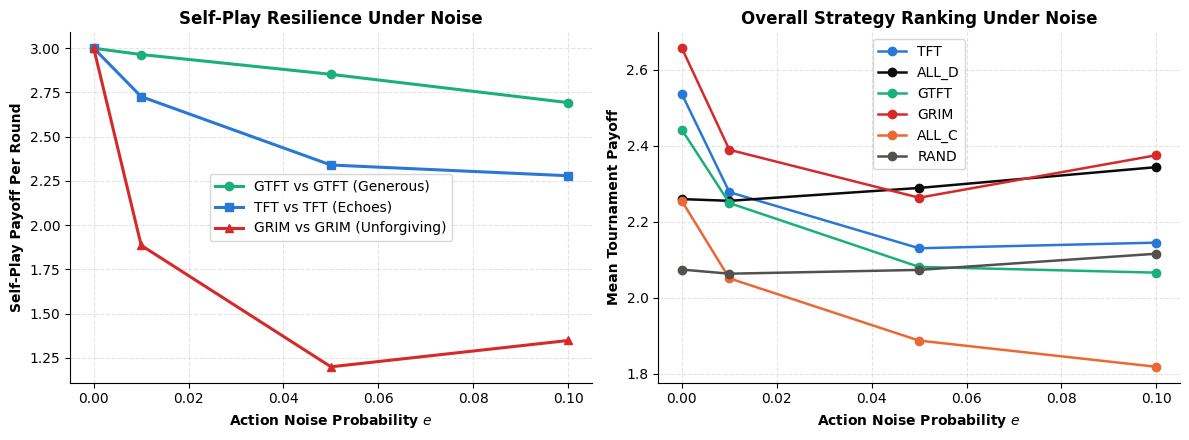

In [5]:
noise_levels = [0.0, 0.01, 0.05, 0.10]
seeds = range(15)

self_play_tft = []
self_play_grim = []
self_play_gtft = []
all_means = {name: [] for name in names}

print("=" * 80)
print("EXERCISE 1: NOISE SWEEP IN THE ITERATED PRISONER'S DILEMMA")
print("=" * 80)

for e in noise_levels:
    _, mat_e, means_e = run_tournament(TOURNAMENT_STRATS, rounds=100, noise=e, seeds=seeds)
    for name, m in zip(names, means_e):
        all_means[name].append(m)
        
    p_tft, p_grim, p_gtft = 0.0, 0.0, 0.0
    for s in seeds:
        rng = np.random.RandomState(s)
        p1, _ = play_match(strat_tft, strat_tft, rounds=100, noise=e, rng=rng)
        p_tft += p1
        rng = np.random.RandomState(s)
        p1, _ = play_match(strat_grim, strat_grim, rounds=100, noise=e, rng=rng)
        p_grim += p1
        rng = np.random.RandomState(s)
        p1, _ = play_match(strat_gtft, strat_gtft, rounds=100, noise=e, rng=rng)
        p_gtft += p1
        
    self_play_tft.append(p_tft / len(seeds))
    self_play_grim.append(p_grim / len(seeds))
    self_play_gtft.append(p_gtft / len(seeds))

    print(f"Noise e = {e:4.2f}:")
    print(f"  Self-play: TFT vs TFT = {self_play_tft[-1]:.2f} | GRIM vs GRIM = {self_play_grim[-1]:.2f} | GTFT vs GTFT = {self_play_gtft[-1]:.2f}")
    print(f"  Means: " + " | ".join(f"{n}: {all_means[n][-1]:.2f}" for n in ["ALL_D", "TFT", "GRIM", "GTFT"]))

# Plots for Exercise 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Self-play under noise
ax1.plot(noise_levels, self_play_gtft, "o-", color=GREEN, linewidth=2.2, label="GTFT vs GTFT (Generous)")
ax1.plot(noise_levels, self_play_tft, "s-", color=BLUE, linewidth=2.2, label="TFT vs TFT (Echoes)")
ax1.plot(noise_levels, self_play_grim, "^-", color=RED, linewidth=2.2, label="GRIM vs GRIM (Unforgiving)")
ax1.set_xlabel("Action Noise Probability $e$", weight="bold")
ax1.set_ylabel("Self-Play Payoff Per Round", weight="bold")
ax1.set_title("Self-Play Resilience Under Noise", weight="bold")
ax1.grid(color=GRID, linestyle="--", alpha=0.7)
ax1.legend()

# Plot 2: Tournament overall means
palette = [BLUE, DARK, GREEN, RED, ORANGE, MUTED]
for n, c in zip(["TFT", "ALL_D", "GTFT", "GRIM", "ALL_C", "RAND"], palette):
    ax2.plot(noise_levels, all_means[n], "o-", color=c, linewidth=1.8, label=n)
ax2.set_xlabel("Action Noise Probability $e$", weight="bold")
ax2.set_ylabel("Mean Tournament Payoff", weight="bold")
ax2.set_title("Overall Strategy Ranking Under Noise", weight="bold")
ax2.grid(color=GRID, linestyle="--", alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.savefig("outputs/lab8_fig2_noise_sweep.png", dpi=200)
plt.show()


### Analysis: Degradation and Survival Under Noise
- **Strategy that degrades most**: **Grim Trigger (GRIM)**. In self-play, GRIM plummets from $3.00$ down to $1.34$ at $e = 0.05$. Because Grim Trigger never forgives, a single inadvertent defection caused by noise permanently destroys cooperation, locking both agents into $(1, 1)$ defection for the rest of the game.
- **Strategy that survives noise best in self-play**: **Generous Tit-for-Tat (GTFT)**. GTFT maintains $2.84$ at $e = 0.05$ and $2.74$ at $e = 0.10$. By forgiving defections with probability $q = 1/3$, it breaks the endless retaliation loops that plague standard TFT ($C-D \leftrightarrow D-C$), successfully restoring mutual cooperation.


---
## 6. Exercise 2 — Continuation Probability $w$ and the Folk Theorem
Matches continue to the next round with probability $w$. The expected discounted payoff per round is:
$$V = (1 - w) \sum_{t=0}^\infty w^t \text{payoff}_t$$
### Algebraic Equating:
- **TFT vs. TFT**: Sustained cooperation yields $R = 3$ every round:
  $$V(\text{TFT vs TFT}) = (1 - w) \sum_{t=0}^\infty w^t R = R = 3.0$$
- **ALL_D vs. TFT**: Exploits TFT in round 0 ($T = 5$), followed by mutual punishment ($P = 1$) forever:
  $$V(\text{ALL\_D vs TFT}) = (1 - w) \left[ T + \sum_{t=1}^\infty w^t P \right] = (1 - w) T + w P = 5(1 - w) + 1w = 5 - 4w$$
- **Critical Threshold**:
  $$3 \ge 5 - 4w \iff 4w \ge 2 \iff w \ge 0.50$$
  General formula:
  $$w^* = \frac{T - R}{T - P} = \frac{5 - 3}{5 - 1} = 0.50$$
  When $w > 0.50$, defecting against Tit-for-Tat no longer pays.


EXERCISE 2: CONTINUATION PROBABILITY w EVALUATION
w      V(TFT vs TFT)   V(ALL_D vs TFT)    Cooperation Pays?
-----------------------------------------------------------------
0.00   3.00            5.00               No (ALL_D wins)
0.20   3.00            4.20               No (ALL_D wins)
0.40   3.00            3.40               No (ALL_D wins)
0.50   3.00            3.00               Yes (TFT >= ALL_D)
0.60   3.00            2.60               Yes (TFT >= ALL_D)
0.80   3.00            1.80               Yes (TFT >= ALL_D)
0.90   3.00            1.40               Yes (TFT >= ALL_D)


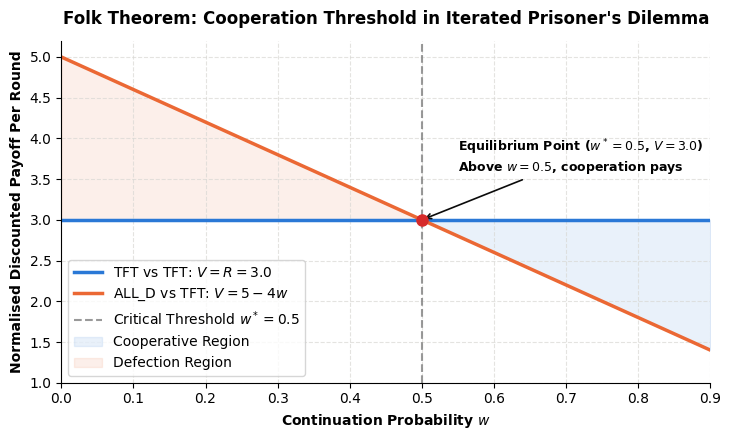

In [6]:
w_values = np.linspace(0.0, 0.9, 100)

v_tft_vs_tft = np.full_like(w_values, 3.0)
v_alld_vs_tft = 5.0 * (1.0 - w_values) + 1.0 * w_values

test_w = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 0.9]
print("=" * 65)
print("EXERCISE 2: CONTINUATION PROBABILITY w EVALUATION")
print("=" * 65)
print(f"{'w':<6} {'V(TFT vs TFT)':<15} {'V(ALL_D vs TFT)':<18} {'Cooperation Pays?'}")
print("-" * 65)
for w in test_w:
    v1 = 3.0
    v2 = 5.0 * (1.0 - w) + 1.0 * w
    pays = "Yes (TFT >= ALL_D)" if v1 >= v2 else "No (ALL_D wins)"
    print(f"{w:<6.2f} {v1:<15.2f} {v2:<18.2f} {pays}")

# Plotting Exercise 2
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(w_values, v_tft_vs_tft, "-", color=BLUE, linewidth=2.5, label="TFT vs TFT: $V = R = 3.0$")
ax.plot(w_values, v_alld_vs_tft, "-", color=ORANGE, linewidth=2.5, label="ALL_D vs TFT: $V = 5 - 4w$")

w_star = 0.5
ax.axvline(w_star, color="gray", linestyle="--", alpha=0.8, label=f"Critical Threshold $w^* = {w_star}$")
ax.plot(w_star, 3.0, "o", color=RED, markersize=8, zorder=5)
ax.annotate(
    f"Equilibrium Point ($w^* = 0.5$, $V = 3.0$)\nAbove $w=0.5$, cooperation pays",
    xy=(w_star, 3.0),
    xytext=(w_star + 0.05, 3.6),
    arrowprops=dict(arrowstyle="->", color=DARK, lw=1.2),
    weight="bold",
    fontsize=9
)

ax.fill_between(w_values, v_tft_vs_tft, v_alld_vs_tft, where=(w_values >= w_star), color=BLUE, alpha=0.1, label="Cooperative Region")
ax.fill_between(w_values, v_tft_vs_tft, v_alld_vs_tft, where=(w_values < w_star), color=ORANGE, alpha=0.1, label="Defection Region")

ax.set_xlabel("Continuation Probability $w$", weight="bold")
ax.set_ylabel("Normalised Discounted Payoff Per Round", weight="bold")
ax.set_title("Folk Theorem: Cooperation Threshold in Iterated Prisoner's Dilemma", weight="bold", pad=12)
ax.set_xlim(0, 0.9)
ax.set_ylim(1, 5.2)
ax.grid(color=GRID, linestyle="--", alpha=0.7)
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig("outputs/lab8_fig3_continuation_prob.png", dpi=200)
plt.show()
